In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load expression data and sample metadata
expression_data = pd.read_csv("../data/processed/GSE107865_expression.csv")
metadata = pd.read_csv("../data/processed/GSE107865_metadata.csv")

# Check dataset dimensions
print("Expression data shape:", expression_data.shape)
print("Metadata shape:", metadata.shape)

# Display first five rows
expression_data.head()

Expression data shape: (24351, 23)
Metadata shape: (22, 6)


,ID_REF,GSM2882184,GSM2882185,GSM2882186,GSM2882187,GSM2882188,GSM2882189,GSM2882190,GSM2882191,GSM2882192,...,GSM2882196,GSM2882197,GSM2882198,GSM2882199,GSM2882200,GSM2882201,GSM2882202,GSM2882203,GSM2882204,GSM2882205
0,AFFX-BkGr-GC03_st,2.005046,1.983293,1.960426,2.035343,1.931051,1.791423,1.784147,1.848812,2.040481,...,1.999921,2.251883,2.302799,2.179057,2.081086,1.929881,2.022703,1.971961,2.157274,1.916600
1,AFFX-BkGr-GC04_st,1.880923,1.974961,1.941266,1.915327,1.842159,1.739075,1.831695,1.810775,1.794120,...,1.863624,1.907798,2.112753,1.976534,1.854095,1.833135,1.839680,1.875990,1.920233,1.857772
2,AFFX-BkGr-GC05_st,1.915240,1.927470,1.966480,1.971324,1.862916,1.751935,1.843181,1.775349,1.771925,...,1.869214,1.908775,2.192303,1.968472,1.851979,1.784312,1.844144,1.921917,1.910708,1.852143
3,AFFX-BkGr-GC06_st,1.944509,2.037043,1.996847,2.010977,1.927292,1.855461,1.874566,1.851702,1.841577,...,1.946240,2.023223,2.182571,2.125019,1.915011,1.820662,1.891860,1.939478,1.986499,1.944962
4,AFFX-BkGr-GC07_st,1.984249,2.012549,2.015486,2.032749,1.975525,1.844585,1.913244,1.882891,1.867593,...,1.947533,1.980183,2.228078,2.053120,1.954136,1.879987,1.934378,1.950612,2.019969,1.953265


In [2]:
#Check missing values in the expression matrix

print("Missing values:")
print(expression_data.isnull().sum().sum())


#Check duplicate probe IDs
print("\nDuplicate probe IDs:")
print(expression_data["ID_REF"].duplicated().sum())

#Check data types
print("\nData types:")
print(expression_data.dtypes.value_counts())

Missing values:
0

Duplicate probe IDs:
0

Data types:
float64    22
str         1
Name: count, dtype: int64


In [3]:
#Check expression value distributions

#Select only expression columns
expression_values = expression_data.iloc[:, 1:]

#Calculate basic statistics
print(expression_values.describe())

         GSM2882184    GSM2882185    GSM2882186    GSM2882187    GSM2882188  \
count  24351.000000  24351.000000  24351.000000  24351.000000  24351.000000   
mean       5.978715      5.971527      5.961539      5.981553      5.960991   
std        2.011519      2.055168      2.060189      2.072614      2.031414   
min        1.422750      1.394399      1.371694      1.306609      1.096438   
25%        4.525237      4.481522      4.460649      4.469002      4.516382   
50%        5.953318      5.930373      5.931994      5.961263      5.933087   
75%        7.273907      7.304899      7.300542      7.320486      7.249700   
max       14.224385     14.227948     14.202564     14.146156     14.186633   

         GSM2882189    GSM2882190    GSM2882191    GSM2882192    GSM2882193  \
count  24351.000000  24351.000000  24351.000000  24351.000000  24351.000000   
mean       5.989042      5.998663      5.983040      5.954819      5.976805   
std        2.072427      2.108854      2.086678    

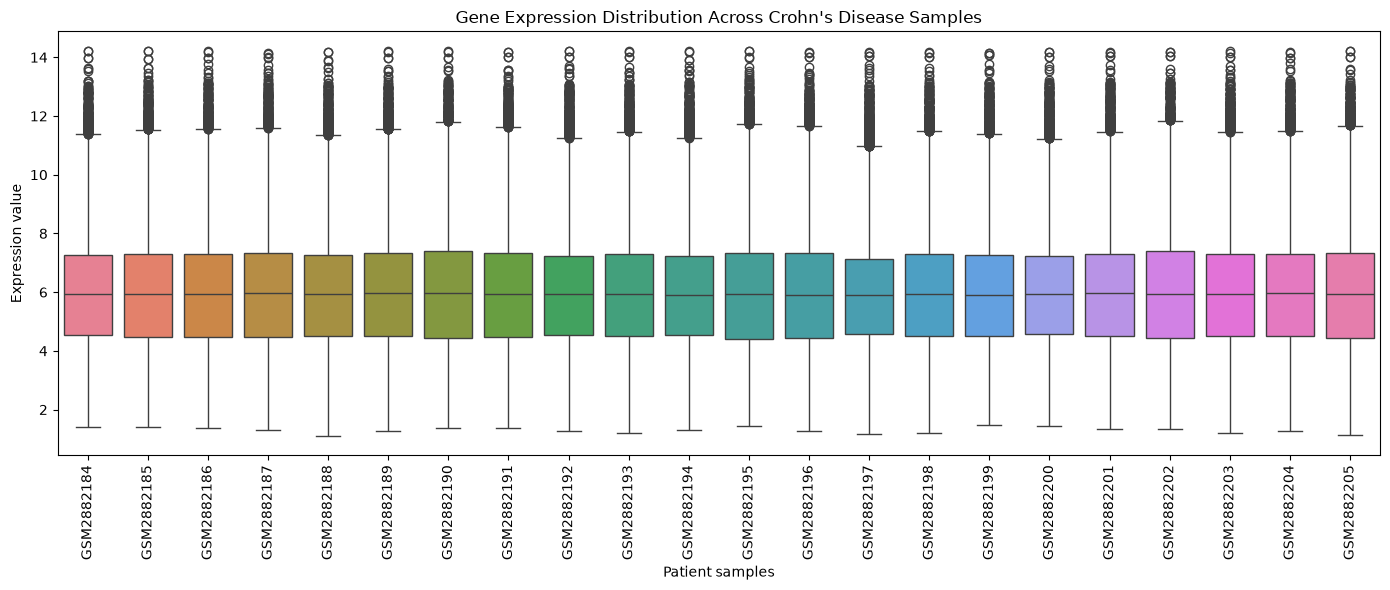

In [4]:
#Create a boxplot

# Compare expression distributions across all patients
plt.figure(figsize=(14, 6))

sns.boxplot(data=expression_values)

plt.xticks(rotation=90)
plt.xlabel("Patient samples")
plt.ylabel("Expression value")
plt.title("Gene Expression Distribution Across Crohn's Disease Samples")

plt.tight_layout()
plt.show()

In [5]:
plt.savefig(
    "../results/figures/GSE107865_expression_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [6]:
# Load GEO sample metadata again
import GEOparse

gse_cd = GEOparse.get_GEO(
    "GSE107865",
    destdir="../data/raw",
    how="brief",
    annotate_gpl=False
)

# Display the microarray platform
for gsm_id, gsm in gse_cd.gsms.items():
    print("Platform ID:", gsm.metadata.get("platform_id", [""])[0])
    break

02-Nov-2026 08:12:35 DEBUG utils - Directory ../data/raw already exists. Skipping.
02-Nov-2026 08:12:35 INFO GEOparse - File already exist: using local version.
02-Nov-2026 08:12:35 INFO GEOparse - Parsing ../data/raw\GSE107865.txt: 
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882184
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882185
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882186
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882187
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882188
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882189
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882190
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882191
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882192
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882193
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882194
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882195
02-Nov-2026 08:12:35 DEBUG GEOparse - SAMPLE: GSM2882196
02-Nov-2026 08:12:35 DEBU

Platform ID: GPL23159


In [7]:
# Load the GPL23159 platform annotation table
annotation = pd.read_csv(
    "../data/raw/GPL23159-184565.txt",
    sep="\t",
    comment="#",
    low_memory=False
)

# Check its dimensions and column names
print("Annotation shape:", annotation.shape)
print("\nAnnotation columns:")
print(annotation.columns.tolist())

# Display the first five rows
annotation.head()

Annotation shape: (27189, 10)

Annotation columns:
['ID', 'probeset_id', 'seqname', 'strand', 'start', 'stop', 'total_probes', 'category', 'SPOT_ID', 'SPOT_ID.1']


,ID,probeset_id,seqname,strand,start,stop,total_probes,category,SPOT_ID,SPOT_ID.1
0,TC0100006437.hg.1,TC0100006437.hg.1,chr1,+,69091,70008,10.0,main,Coding,NM_001005484 // RefSeq // Homo sapiens olfacto...
1,TC0100006476.hg.1,TC0100006476.hg.1,chr1,+,924880,944581,10.0,main,Multiple_Complex,NM_152486 // RefSeq // Homo sapiens sterile al...
2,TC0100006479.hg.1,TC0100006479.hg.1,chr1,+,960587,965719,10.0,main,Multiple_Complex,NM_198317 // RefSeq // Homo sapiens kelch-like...
3,TC0100006480.hg.1,TC0100006480.hg.1,chr1,+,966497,975865,10.0,main,Multiple_Complex,NM_001160184 // RefSeq // Homo sapiens pleckst...
4,TC0100006483.hg.1,TC0100006483.hg.1,chr1,+,1001138,1014541,10.0,main,Multiple_Complex,NM_005101 // RefSeq // Homo sapiens ISG15 ubiq...


In [8]:
#Display annotaion descriptions for the first 10 probes

annotation[["ID", "SPOT_ID.1"]].head(10)

,ID,SPOT_ID.1
0,TC0100006437.hg.1,NM_001005484 // RefSeq // Homo sapiens olfacto...
1,TC0100006476.hg.1,NM_152486 // RefSeq // Homo sapiens sterile al...
2,TC0100006479.hg.1,NM_198317 // RefSeq // Homo sapiens kelch-like...
3,TC0100006480.hg.1,NM_001160184 // RefSeq // Homo sapiens pleckst...
4,TC0100006483.hg.1,NM_005101 // RefSeq // Homo sapiens ISG15 ubiq...
5,TC0100006486.hg.1,NM_001305275 // RefSeq // Homo sapiens agrin (...
6,TC0100006490.hg.1,NR_038869 // RefSeq // Homo sapiens long inter...
7,TC0100006492.hg.1,NM_001130045 // RefSeq // Homo sapiens tubulin...
8,TC0100006494.hg.1,NM_080605 // RefSeq // Homo sapiens UDP-Gal:be...
9,TC0100006497.hg.1,NM_001130413 // RefSeq // Homo sapiens sodium ...


In [9]:
#Display complete annotation descriptions
for i in range(5):
    print("Probe ID:", annotation.loc[i, "ID"])
    print("Annotation:", annotation.loc[i, "SPOT_ID.1"])
    print("-" *80)

Probe ID: TC0100006437.hg.1
Annotation: NM_001005484 // RefSeq // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000335137 // ENSEMBL // olfactory receptor, family 4, subfamily F, member 5 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000003223 // Havana transcript // olfactory receptor, family 4, subfamily F, member 5[gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// uc001aal.1 // UCSC Genes // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// CCDS30547.1 // ccdsGene // olfactory receptor, family 4, subfamily F, member 5 [Source:HGNC Symbol;Acc:HGNC:14825] // chr1 // 100 // 100 // 0 // --- // 0
--------------------------------------------------------------------------------
Probe ID: TC0100006476.hg.1
Annotat

In [10]:
# Count annotation records containing HGNC gene symbols

print("Total probes:", len(annotation))

print("Records containing HGNC symbols:",
      annotation["SPOT_ID.1"].str.contains("HGNC Symbol", na=False).sum())

Total probes: 27189
Records containing HGNC symbols: 19589


In [11]:
# Display annotation descriptions containing HGNC information

hgnc_annotations = annotation[
    annotation["SPOT_ID.1"].str.contains("HGNC Symbol", na=False)
]

hgnc_annotations[["ID", "SPOT_ID.1"]].head(10)

,ID,SPOT_ID.1
0,TC0100006437.hg.1,NM_001005484 // RefSeq // Homo sapiens olfacto...
1,TC0100006476.hg.1,NM_152486 // RefSeq // Homo sapiens sterile al...
2,TC0100006479.hg.1,NM_198317 // RefSeq // Homo sapiens kelch-like...
3,TC0100006480.hg.1,NM_001160184 // RefSeq // Homo sapiens pleckst...
4,TC0100006483.hg.1,NM_005101 // RefSeq // Homo sapiens ISG15 ubiq...
5,TC0100006486.hg.1,NM_001305275 // RefSeq // Homo sapiens agrin (...
6,TC0100006490.hg.1,NR_038869 // RefSeq // Homo sapiens long inter...
7,TC0100006492.hg.1,NM_001130045 // RefSeq // Homo sapiens tubulin...
8,TC0100006494.hg.1,NM_080605 // RefSeq // Homo sapiens UDP-Gal:be...
9,TC0100006497.hg.1,NM_001130413 // RefSeq // Homo sapiens sodium ...


In [12]:
#Display the complete annotation description for the first probe

print(annotation.loc[0, "SPOT_ID.1"])

NM_001005484 // RefSeq // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000335137 // ENSEMBL // olfactory receptor, family 4, subfamily F, member 5 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000003223 // Havana transcript // olfactory receptor, family 4, subfamily F, member 5[gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// uc001aal.1 // UCSC Genes // Homo sapiens olfactory receptor, family 4, subfamily F, member 5 (OR4F5), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// CCDS30547.1 // ccdsGene // olfactory receptor, family 4, subfamily F, member 5 [Source:HGNC Symbol;Acc:HGNC:14825] // chr1 // 100 // 100 // 0 // --- // 0


In [13]:
# Extract gene symbols from annotation descriptions

annotation["gene_symbol"] = annotation["SPOT_ID.1"].str.extract(r"\((.*?)\)")

# Display the first 10 gene symbols
annotation[["ID", "gene_symbol"]].head(10)

,ID,gene_symbol
0,TC0100006437.hg.1,OR4F5
1,TC0100006476.hg.1,SAMD11
2,TC0100006479.hg.1,KLHL17
3,TC0100006480.hg.1,PLEKHN1
4,TC0100006483.hg.1,ISG15
5,TC0100006486.hg.1,AGRN
6,TC0100006490.hg.1,LINC01342
7,TC0100006492.hg.1,TTLL10
8,TC0100006494.hg.1,B3GALT6
9,TC0100006497.hg.1,SCNN1D


In [14]:
# Count missing gene symbols

print("Total probes:", len(annotation))
print("Missing gene symbols:", annotation["gene_symbol"].isna().sum())
print("Available gene symbols:", annotation["gene_symbol"].notna().sum())

Total probes: 27189
Missing gene symbols: 6892
Available gene symbols: 20297


In [15]:
#Count unique gene symbols

print("Unique gene symbols:",
      annotation["gene_symbol"].nunique())

#Count duplicated gene symbols
print("Duplicate gene symbols:",
      annotation["gene_symbol"].duplicated().sum())

Unique gene symbols: 17618
Duplicate gene symbols: 9570


In [16]:
#Count how many probes map to each gene
gene_counts = annotation["gene_symbol"].value_counts()

#Display the 10 genes with the most probes
gene_counts.head(10)

gene_symbol
s                  476
Drosophila         105
gene/pseudogene     87
S. cerevisiae       75
ubiquinone          66
yeast               60
Hsp40               48
C. elegans          46
putative            41
GEF                 39
Name: count, dtype: int64

In [17]:
# Count the different annotation categories
annotation["category"].value_counts()

category
main                          20893
control                        2838
normgene->exon                 2197
normgene->intron                612
main->unmapped                  555
control->affx->ercc->step        63
control->bgp->antigenomic        23
control->affx->bac_spike          4
control->affx->polya_spike        4
Name: count, dtype: int64

In [18]:
#Keep probes classified as main
main_probes = annotation[annotation["category"] == "main"].copy()

#Check the number of main probes
print("Main probes:", len(main_probes))

#Check how many have a gene symbol
print("Missing gene symbols:", main_probes["gene_symbol"].isna().sum())

#Display the first 10 records
main_probes[["ID", "gene_symbol"]].head(10)

Main probes: 20893
Missing gene symbols: 707


,ID,gene_symbol
0,TC0100006437.hg.1,OR4F5
1,TC0100006476.hg.1,SAMD11
2,TC0100006479.hg.1,KLHL17
3,TC0100006480.hg.1,PLEKHN1
4,TC0100006483.hg.1,ISG15
5,TC0100006486.hg.1,AGRN
6,TC0100006490.hg.1,LINC01342
7,TC0100006492.hg.1,TTLL10
8,TC0100006494.hg.1,B3GALT6
9,TC0100006497.hg.1,SCNN1D


In [19]:
# Remove probes without a gene symbol for this count
main_genes = main_probes.dropna(subset=["gene_symbol"])

#Count unique gene symbols
print("Probes with gene symbols:", len(main_genes))
print("Unique genes:", main_genes["gene_symbol"].nunique())
print("Duplicate probe entries:", main_genes["gene_symbol"].duplicated().sum())

Probes with gene symbols: 20186
Unique genes: 17614
Duplicate probe entries: 2572


In [20]:
# Find genes represented by multiple probes
duplicate_genes = main_genes[
    main_genes["gene_symbol"].duplicated(keep=False)
]

# Count probes for each duplicated gene
duplicate_counts = duplicate_genes["gene_symbol"].value_counts()

# Display the 10 genes with the most probes
duplicate_counts.head(10)

gene_symbol
s                  476
Drosophila         105
gene/pseudogene     84
S. cerevisiae       75
yeast               60
Hsp40               48
ubiquinone          48
C. elegans          46
putative            41
GEF                 39
Name: count, dtype: int64

In [21]:
#inspect the annotation text for these entries

# Inspect the original annotation for the suspicious entries
annotation.loc[
    annotation["gene_symbol"].isin(["s", "Drosophila", "yeast"]),
    ["ID", "SPOT_ID.1", "gene_symbol"]
].head(10)

,ID,SPOT_ID.1,gene_symbol
73,TC0100006877.hg.1,MIIP.lAug10-unspliced // Ace View // Transcrip...,s
80,TC0100006906.hg.1,C1orf158.eAug10-unspliced // Ace View // Trans...,s
142,TC0100007305.hg.1,KDM1A.kAug10-unspliced // Ace View // Transcri...,s
252,TC0100007858.hg.1,NM_016037 // RefSeq // Homo sapiens UTP11-like...,yeast
260,TC0100007922.hg.1,PPIE.uAug10 // Ace View // Transcript Identifi...,s
262,TC0100007940.hg.1,"NM_001105530 // RefSeq // Homo sapiens CAP, ad...",yeast
319,TC0100008151.hg.1,RAD54L.iAug10-unspliced // Ace View // Transcr...,s
346,TC0100008342.hg.1,PODN.kAug10-unspliced // Ace View // Transcrip...,s
356,TC0100008411.hg.1,ENST00000415336.1 // lncRNAWiki // N/A // chr1...,s
365,TC0100008536.hg.1,NM_176877 // RefSeq // Homo sapiens InaD-like ...,Drosophila


In [22]:
#inspect the original annotaiton records

# Inspect one incorrectly extracted annotation
print("Incorrect annotation:")
print(annotation.loc[73, "SPOT_ID.1"])

# Inspect one correctly extracted annotation
print("\nCorrect annotation:")
print(annotation.loc[4, "SPOT_ID.1"])

Incorrect annotation:
MIIP.lAug10-unspliced // Ace View // Transcript Identified by AceView, Entrez Gene ID(s) 60672 // chr1 // 100 // 100 // 0 // --- // 0

Correct annotation:
NM_005101 // RefSeq // Homo sapiens ISG15 ubiquitin-like modifier (ISG15), mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000379389 // ENSEMBL // ISG15 ubiquitin-like modifier [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000624652 // ENSEMBL // ISG15 ubiquitin-like modifier [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000624697 // ENSEMBL // ISG15 ubiquitin-like modifier [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// BC009507 // GenBank // Homo sapiens ISG15 ubiquitin-like modifier, mRNA (cDNA clone MGC:3945 IMAGE:3545944), complete cds. // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000097989 // Havana tra

In [23]:
# Extract gene symbols from human RefSeq annotations
annotation["gene_symbol"] = annotation["SPOT_ID.1"].str.extract(
    r"Homo sapiens .*?\(([A-Z0-9-]+)\), mRNA"
)

# Check the extracted gene symbols
annotation[["ID", "gene_symbol"]].head(10)

,ID,gene_symbol
0,TC0100006437.hg.1,OR4F5
1,TC0100006476.hg.1,SAMD11
2,TC0100006479.hg.1,KLHL17
3,TC0100006480.hg.1,NaN
4,TC0100006483.hg.1,ISG15
5,TC0100006486.hg.1,NaN
6,TC0100006490.hg.1,NaN
7,TC0100006492.hg.1,NaN
8,TC0100006494.hg.1,B3GALT6
9,TC0100006497.hg.1,NaN


In [24]:
# Count missing and available gene symbols
print("Total probes:", len(annotation))
print("Missing gene symbols:", annotation["gene_symbol"].isna().sum())
print("Available gene symbols:", annotation["gene_symbol"].notna().sum())
print("Unique gene symbols:", annotation["gene_symbol"].nunique())

Total probes: 27189
Missing gene symbols: 17548
Available gene symbols: 9641
Unique gene symbols: 9547


In [25]:
# Inspect annotation records without an extracted gene symbol
missing_genes = annotation[annotation["gene_symbol"].isna()]

missing_genes[["ID", "SPOT_ID.1"]].head(15)

,ID,SPOT_ID.1
3,TC0100006480.hg.1,NM_001160184 // RefSeq // Homo sapiens pleckst...
5,TC0100006486.hg.1,NM_001305275 // RefSeq // Homo sapiens agrin (...
6,TC0100006490.hg.1,NR_038869 // RefSeq // Homo sapiens long inter...
7,TC0100006492.hg.1,NM_001130045 // RefSeq // Homo sapiens tubulin...
9,TC0100006497.hg.1,NM_001130413 // RefSeq // Homo sapiens sodium ...
14,TC0100006516.hg.1,NM_022834 // RefSeq // Homo sapiens von Willeb...
16,TC0100006524.hg.1,NM_001170686 // RefSeq // Homo sapiens mindbom...
19,TC0100006550.hg.1,NM_001033581 // RefSeq // Homo sapiens protein...
21,TC0100006571.hg.1,hsa_circ_0000009 // circbase // Memczak2013 AL...
23,TC0100006587.hg.1,NM_001195736 // RefSeq // Homo sapiens family ...


In [26]:
# Inspect the complete annotation for one missing gene
print(missing_genes["SPOT_ID.1"].iloc[0])

NM_001160184 // RefSeq // Homo sapiens pleckstrin homology domain containing, family N member 1 (PLEKHN1), transcript variant 2, mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// NM_032129 // RefSeq // Homo sapiens pleckstrin homology domain containing, family N member 1 (PLEKHN1), transcript variant 1, mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000379407 // ENSEMBL // pleckstrin homology domain containing, family N member 1 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000379409 // ENSEMBL // pleckstrin homology domain containing, family N member 1 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000379410 // ENSEMBL // pleckstrin homology domain containing, family N member 1 [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000480267 // ENSEMBL // pleckstrin homology domain containi

In [27]:
# Extract the RefSeq annotation
refseq = annotation["SPOT_ID.1"].str.extract(
    r"RefSeq // Homo sapiens.*?\((.*?)\)"
)

# Store the extracted gene symbols
annotation["gene_symbol"] = refseq[0]

# Check the results
annotation[["ID", "gene_symbol"]].head(10)

,ID,gene_symbol
0,TC0100006437.hg.1,OR4F5
1,TC0100006476.hg.1,SAMD11
2,TC0100006479.hg.1,KLHL17
3,TC0100006480.hg.1,PLEKHN1
4,TC0100006483.hg.1,ISG15
5,TC0100006486.hg.1,AGRN
6,TC0100006490.hg.1,LINC01342
7,TC0100006492.hg.1,TTLL10
8,TC0100006494.hg.1,B3GALT6
9,TC0100006497.hg.1,SCNN1D


In [28]:
# Count missing and available gene symbols
print("Total probes:", len(annotation))
print("Missing gene symbols:", annotation["gene_symbol"].isna().sum())
print("Available gene symbols:", annotation["gene_symbol"].notna().sum())

Total probes: 27189
Missing gene symbols: 7665
Available gene symbols: 19524


In [29]:
# Display the first 10 probes without a gene symbol
missing_genes = annotation[annotation["gene_symbol"].isna()]

missing_genes[["ID", "SPOT_ID.1"]].head(10)

,ID,SPOT_ID.1
21,TC0100006571.hg.1,hsa_circ_0000009 // circbase // Memczak2013 AL...
47,TC0100006755.hg.1,hsa_circ_0000013 // circbase // Memczak2013 AN...
73,TC0100006877.hg.1,MIIP.lAug10-unspliced // Ace View // Transcrip...
80,TC0100006906.hg.1,C1orf158.eAug10-unspliced // Ace View // Trans...
107,TC0100007091.hg.1,hsa_circ_0092359 // circbase // Zhang2013 ALT_...
131,TC0100007255.hg.1,hsa_circ_0008411 // circbase // Jeck2013 ANTIS...
142,TC0100007305.hg.1,KDM1A.kAug10-unspliced // Ace View // Transcri...
172,TC0100007471.hg.1,hsa_circ_0092329 // circbase // Zhang2013 ALT_...
183,TC0100007514.hg.1,hsa_circ_0000035 // circbase // Memczak2013 AN...
201,TC0100007575.hg.1,hsa_circ_0000040 // circbase // Memczak2013 AL...


In [30]:
# Count annotation sources among probes without gene symbols
missing_genes["SPOT_ID.1"].str.split(" // ").str[1].value_counts().head(10)

SPOT_ID.1
ENSEMBL              934
circbase             435
Ace View             402
Havana transcript     69
lncRNAWiki            42
GenBank               34
UCSC Genes             8
Name: count, dtype: int64

In [31]:
#inspect an ENSEMBL annotation

# Select probes with missing RefSeq gene symbols
# and ENSEMBL as their annotation source

ensembl_missing = missing_genes[
    missing_genes["SPOT_ID.1"].str.contains("ENSEMBL", na=False)
]

# Display one complete annotation
print(ensembl_missing["SPOT_ID.1"].iloc[0])

BC072388 // GenBank // Homo sapiens 3-oxoacid CoA transferase 2, mRNA (cDNA clone MGC:87924 IMAGE:5588771), complete cds. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000447263 // ENSEMBL // 3-oxoacid CoA transferase 2 pseudogene 1 [gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000025657 // Havana transcript // 3-oxoacid CoA transferase 2 (OXCT2) pseudogene[gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0


In [32]:
# Display one complete annotation from the missing ENSEMBL entries
print(ensembl_missing["SPOT_ID.1"].iloc[0])

BC072388 // GenBank // Homo sapiens 3-oxoacid CoA transferase 2, mRNA (cDNA clone MGC:87924 IMAGE:5588771), complete cds. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000447263 // ENSEMBL // 3-oxoacid CoA transferase 2 pseudogene 1 [gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000025657 // Havana transcript // 3-oxoacid CoA transferase 2 (OXCT2) pseudogene[gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0


In [33]:
for item in ensembl_missing["SPOT_ID.1"].head(5):
    print(item)
    print("--------------------")

BC072388 // GenBank // Homo sapiens 3-oxoacid CoA transferase 2, mRNA (cDNA clone MGC:87924 IMAGE:5588771), complete cds. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000447263 // ENSEMBL // 3-oxoacid CoA transferase 2 pseudogene 1 [gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0 /// OTTHUMT00000025657 // Havana transcript // 3-oxoacid CoA transferase 2 (OXCT2) pseudogene[gene_biotype:unprocessed_pseudogene transcript_biotype:unprocessed_pseudogene] // chr1 // 100 // 100 // 0 // --- // 0
--------------------
ENST00000415336.1 // lncRNAWiki // N/A // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000433690.1 // lncRNAWiki // N/A // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000436033.1 // lncRNAWiki // N/A // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000443284.1 // lncRNAWiki // N/A // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000455380.1 // lncRNAWiki // N/A // chr1 // 100 // 100 // 0 // --- // 0 /// OT

In [34]:
# Find annotations containing protein-coding information
protein_coding = main_probes[
    main_probes["SPOT_ID.1"].str.contains(
        "gene_biotype:protein_coding",
        case=False,
        na=False
    )
]

print("Protein-coding annotated probes:", len(protein_coding))

Protein-coding annotated probes: 19350


In [35]:
# Keep protein-coding annotated probes
protein_coding_genes = protein_coding[
    protein_coding["gene_symbol"].notna()
]

# Count unique gene symbols
print("Unique protein-coding genes:",
      protein_coding_genes["gene_symbol"].nunique())

Unique protein-coding genes: 17094


In [36]:
# Recreate the main probe dataset
main_probes = annotation[annotation["category"] == "main"].copy()

# Keep protein-coding probes
protein_coding = main_probes[
    main_probes["SPOT_ID.1"].str.contains(
        "gene_biotype:protein_coding",
        case=False,
        na=False
    )
].copy()

# Keep probes with an extracted gene symbol
protein_coding_genes = protein_coding[
    protein_coding["gene_symbol"].notna()
].copy()

print("Protein-coding probes:", len(protein_coding))
print("Probes with gene symbols:", len(protein_coding_genes))
print("Unique gene symbols:", protein_coding_genes["gene_symbol"].nunique())

Protein-coding probes: 19350
Probes with gene symbols: 18922
Unique gene symbols: 17071


In [37]:
gene_counts = protein_coding_genes["gene_symbol"].value_counts()

duplicate_genes = gene_counts[gene_counts > 1]

print("Genes with multiple probes:", len(duplicate_genes))
print("Maximum probes for one gene:", gene_counts.max())

Genes with multiple probes: 410
Maximum probes for one gene: 93


In [38]:
# Inspect the annotation descriptions for incorrectly extracted symbols
protein_coding_genes[
    protein_coding_genes["gene_symbol"].isin(
        ["Drosophila", "yeast", "S. cerevisiae", "gene/pseudogene"]
    )
][["ID", "gene_symbol", "SPOT_ID.1"]].head(5)

,ID,gene_symbol,SPOT_ID.1
76,TC0100006884.hg.1,S. cerevisiae,NM_015378 // RefSeq // Homo sapiens vacuolar p...
252,TC0100007858.hg.1,yeast,NM_016037 // RefSeq // Homo sapiens UTP11-like...
262,TC0100007940.hg.1,yeast,"NM_001105530 // RefSeq // Homo sapiens CAP, ad..."
318,TC0100008150.hg.1,S. cerevisiae,NM_001142548 // RefSeq // Homo sapiens RAD54-l...
365,TC0100008536.hg.1,Drosophila,NM_176877 // RefSeq // Homo sapiens InaD-like ...


In [39]:
# Display the complete annotation for one incorrectly mapped probe
print(annotation.loc[76, "SPOT_ID.1"])

NM_015378 // RefSeq // Homo sapiens vacuolar protein sorting 13 homolog D (S. cerevisiae) (VPS13D), transcript variant 1, mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// NM_018156 // RefSeq // Homo sapiens vacuolar protein sorting 13 homolog D (S. cerevisiae) (VPS13D), transcript variant 2, mRNA. // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000011700 // ENSEMBL // vacuolar protein sorting 13 homolog D (S. cerevisiae) [gene_biotype:protein_coding transcript_biotype:protein_coding] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000460333 // ENSEMBL // vacuolar protein sorting 13 homolog D (S. cerevisiae) [gene_biotype:protein_coding transcript_biotype:retained_intron] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000466732 // ENSEMBL // vacuolar protein sorting 13 homolog D (S. cerevisiae) [gene_biotype:protein_coding transcript_biotype:nonsense_mediated_decay] // chr1 // 100 // 100 // 0 // --- // 0 /// ENST00000469054 // ENSEMBL // vacuolar protein sorting 13 homolog D (S. cer

In [40]:
import re

def extract_gene_symbol(description):
    for entry in description.split(" /// "):
        if " // RefSeq // Homo sapiens " in entry:
            match = re.search(
                r"\(([A-Za-z0-9_-]+)\)(?:, transcript variant \d+)?, mRNA",
                entry
            )
            if match:
                return match.group(1)

    return None

annotation["gene_symbol"] = annotation["SPOT_ID.1"].apply(
    extract_gene_symbol
)

In [41]:
annotation.loc[76, ["ID", "gene_symbol"]]

ID             TC0100006884.hg.1
gene_symbol               VPS13D
Name: 76, dtype: str

In [42]:
# Keep main protein-coding probes with valid gene symbols
main_probes = annotation[annotation["category"] == "main"].copy()

protein_coding = main_probes[
    main_probes["SPOT_ID.1"].str.contains(
        "gene_biotype:protein_coding",
        case=False,
        na=False
    )
].copy()

protein_coding_genes = protein_coding[
    protein_coding["gene_symbol"].notna()
].copy()

# Check duplicated gene symbols
gene_counts = protein_coding_genes["gene_symbol"].value_counts()

print("Probes with gene symbols:", len(protein_coding_genes))
print("Unique genes:", protein_coding_genes["gene_symbol"].nunique())
print("Genes with multiple probes:", (gene_counts > 1).sum())

gene_counts.head(10)

Probes with gene symbols: 18504
Unique genes: 18415
Genes with multiple probes: 72


gene_symbol
USP17L25    6
TP53TG3B    5
CT47A10     4
OR4F29      3
OPN1MW      3
H2AFB1      3
F8A2        3
TSPY3       3
PRR20B      3
NPIPA7      3
Name: count, dtype: int64

In [43]:
# Match expression probes with their gene symbols
gene_expression = expression_data.merge(
    protein_coding_genes[["ID", "gene_symbol"]],
    left_on="ID_REF",
    right_on="ID",
    how="inner"
)

# Keep sample expression columns
sample_columns = expression_data.columns.drop("ID_REF")

# Calculate mean expression for each gene
gene_expression = gene_expression.groupby("gene_symbol")[sample_columns].mean()

# Save the gene-level expression matrix
gene_expression.to_csv(
    "../data/processed/GSE107865_gene_expression.csv"
)

print("Gene-level expression matrix:", gene_expression.shape)
gene_expression.head()

Gene-level expression matrix: (18415, 22)


,GSM2882184,GSM2882185,GSM2882186,GSM2882187,GSM2882188,GSM2882189,GSM2882190,GSM2882191,GSM2882192,GSM2882193,...,GSM2882196,GSM2882197,GSM2882198,GSM2882199,GSM2882200,GSM2882201,GSM2882202,GSM2882203,GSM2882204,GSM2882205
gene_symbol,,,,,,,,,,,,,,,,,,,,,
A1CF,3.098193,3.582092,3.334955,3.752183,3.170890,2.970676,2.846252,2.965725,3.150114,3.199408,...,2.726258,3.033491,3.215207,2.897814,3.577815,3.314514,2.696658,3.076346,3.825023,3.565710
A2M,4.575985,4.733894,4.996993,4.749530,4.829959,4.527423,4.826516,4.917678,4.739324,4.837901,...,4.803063,4.479832,4.761790,5.083660,4.864638,5.193284,4.557641,4.437799,4.942773,5.055844
A2ML1,3.029300,3.207219,3.747547,2.944160,3.629362,3.455732,3.198368,3.552164,3.408041,3.612756,...,3.514253,4.369752,3.522663,3.415108,3.664185,3.660125,3.044432,3.345762,3.328837,3.289201
A3GALT2,4.976682,4.719185,4.166586,4.953965,5.095011,4.484892,4.557394,4.159950,5.252123,4.137598,...,4.913479,5.578547,4.438381,4.979575,5.260611,4.798243,4.386918,5.203570,4.641066,4.746553
A4GALT,4.746492,4.191834,4.685767,4.495422,4.580468,4.797583,4.819020,4.997457,5.001440,4.914801,...,4.696491,5.063409,4.598139,4.239566,4.471909,5.008804,4.733079,5.076032,4.680738,3.787935


In [45]:
# Load the sample metadata
metadata_cd = pd.read_csv(
    "../data/processed/GSE107865_metadata.csv"
)

# Match metadata order to the expression matrix
metadata_aligned = metadata_cd.set_index("sample_id").loc[
    gene_expression.columns
].reset_index()

print("Samples matched:", len(metadata_aligned))
print("\nTreatment response groups:")
print(metadata_aligned["response"].value_counts())

Samples matched: 22

Treatment response groups:
response
Responder        17
Non-responder     5
Name: count, dtype: int64


In [46]:
# Save metadata in the same order as the expression matrix
metadata_aligned.to_csv(
    "../data/processed/GSE107865_metadata_aligned.csv",
    index=False
)

# Stage 3: Differential Gene Expression

In [47]:
import numpy as np
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [48]:
#Load gene expression and aligned patient metadata
gene_expression = pd.read_csv(
    "../data/processed/GSE107865_gene_expression.csv",
    index_col="gene_symbol"
    )

metadata_aligned = pd.read_csv(
    "../data/processed/GSE107865_metadata_aligned.csv"
)

print("Expression matrix:", gene_expression.shape)
print("Metadata:", metadata_aligned.shape)

Expression matrix: (18415, 22)
Metadata: (22, 6)


In [49]:
#compare responders and non-responders

#Identify samples belonging to each reponse group
responders= metadata_aligned.loc[
    metadata_aligned["response"] == "Responder", "sample_id"
]

non_responders = metadata_aligned.loc[
    metadata_aligned["response"] =="Non-responder", "sample_id"
]

results = []

# Test each gene for differences between response groups
for gene in gene_expression.index:
    group1 = gene_expression.loc[gene, responders]
    group2 = gene_expression.loc[gene, non_responders]

    statistic, p_value = ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    results.append({
        "gene": gene,
        "mean_responder": group1.mean(),
        "mean_non_responder": group2.mean(),
        "log2_difference": group2.mean() - group1.mean(),
        "p_value": p_value
    })

de_results = pd.DataFrame(results)

print("Genes tested:", len(de_results))
de_results.head()

Genes tested: 18415


,gene,mean_responder,mean_non_responder,log2_difference,p_value
0,A1CF,3.244181,3.052815,-0.191366,0.299174
1,A2M,4.785448,4.738511,-0.046937,0.557971
2,A2ML1,3.488050,3.330010,-0.158040,0.254059
3,A3GALT2,4.770867,4.800067,0.029200,0.894808
4,A4GALT,4.686012,4.656684,-0.029328,0.856727


In [50]:
#Multiple-testing correction

#Correct p-values using the Benjamini-Hochberg method
de_results["adjusted_p_value"] = multipletests(
    de_results["p_value"],
    method="fdr_bh"
)[1]

# Rename the expression difference column
de_results = de_results.rename(
    columns={"log2_difference": "expression_difference"}
)

# Sort genes by adjusted p-value
de_results = de_results.sort_values("adjusted_p_value")

de_results.head(10)

,gene,mean_responder,mean_non_responder,expression_difference,p_value,adjusted_p_value
13098,RELT,8.118649,7.869576,-0.249073,0.000002,0.044438
15929,TIAM2,5.104112,4.171481,-0.932631,0.000014,0.056708
14540,SLC43A2,9.504108,9.089421,-0.414687,0.000008,0.056708
13686,S100B,5.002561,4.337941,-0.664619,0.000013,0.056708
9918,NADK,9.746960,9.271473,-0.475487,0.000022,0.056708
10154,NEXN,4.554739,3.983719,-0.571020,0.000020,0.056708
18178,ZNF619,5.310063,5.866873,0.556811,0.000024,0.056708
5326,FAM47E,2.493278,2.024917,-0.468361,0.000025,0.056708
4293,DMWD,6.236720,6.753629,0.516909,0.000046,0.094873
14865,SOD2,11.632968,11.149889,-0.483079,0.000097,0.179265


In [51]:
#Save the complete differential-expression results
de_results.to_csv(
    "../results/tables/GSE107865_differential_expression.csv",
    index=False
)

#Save the top 20 genes separately
top_20_genes = de_results.head(20)

top_20_genes.to_csv(
    "../results/tables/GSE107865_top20_genes.csv",
    index=False

)

# Count genes significant at FDR < 0.05
significant_genes = de_results[
    de_results["adjusted_p_value"] < 0.05
]

print("Total genes tested:", len(de_results))
print("Significant genes (FDR < 0.05):", len(significant_genes))
print("CSV files saved successfully.")

Total genes tested: 18415
Significant genes (FDR < 0.05): 1
CSV files saved successfully.


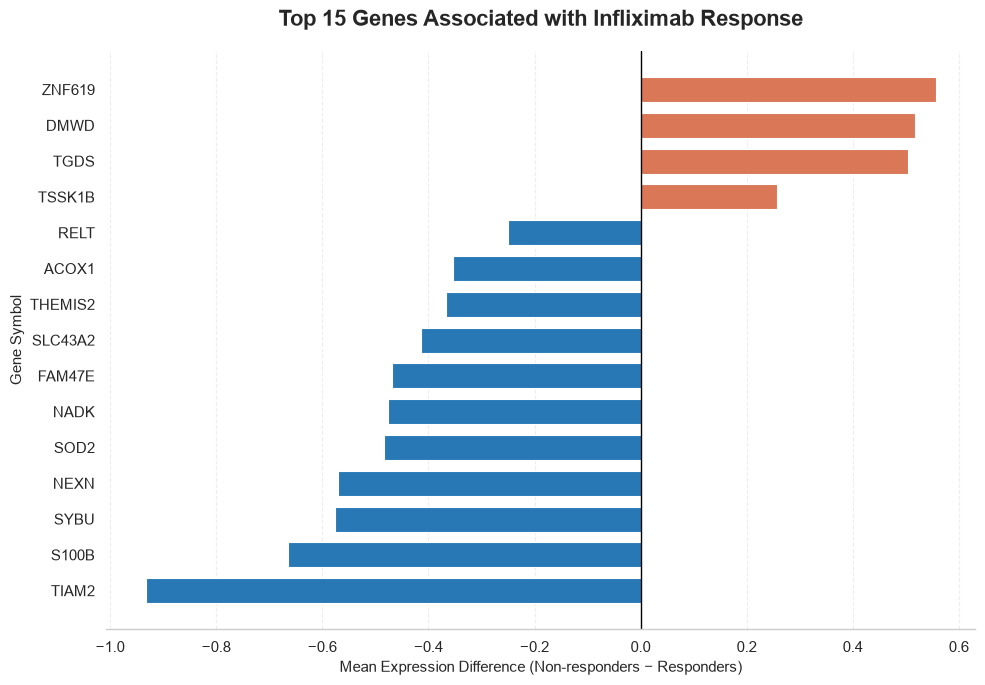

In [53]:
#Visulase the top 15 genes

import matplotlib.pyplot as plt
import seaborn as sns

# Select the 15 genes ranked by adjusted p-value
top_15 = de_results.head(15).sort_values("expression_difference")

# Use a clean scientific plotting style
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

fig, ax = plt.subplots(figsize=(10, 7))

# Different colours indicate the direction of expression difference
colors = [
    "#2878B5" if value < 0 else "#D97757"
    for value in top_15["expression_difference"]
]

ax.barh(
    top_15["gene"],
    top_15["expression_difference"],
    color=colors,
    height=0.7
)

# Reference line showing no expression difference
ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Top 15 Genes Associated with Infliximab Response",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Mean Expression Difference (Non-responders − Responders)",
    fontsize=11
)
ax.set_ylabel("Gene Symbol", fontsize=11)

ax.grid(axis="y", visible=False)
ax.grid(axis="x", linestyle="--", alpha=0.35)

sns.despine(left=True, bottom=False)
plt.tight_layout()

# Save the publication-quality figure
plt.savefig(
    "../results/figures/top15_differential_expression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
#Feature selection

# Transpose so patients are rows and genes are columns
X = gene_expression.T

# Encode treatment response as numerical labels
y = metadata["response"].map({
    "Responder": 1,
    "Non-responder": 0
})

print("Feature matrix:", X.shape)
print("Response labels:", y.shape)
print("\nResponse distribution:")
print(y.value_counts())

Feature matrix: (22, 18415)
Response labels: (22,)

Response distribution:
response
1    17
0     5
Name: count, dtype: int64


In [55]:
#feature selection method
# Match response labels to the expression matrix sample order
y.index = metadata["sample_id"]
y = y.loc[X.index]

print("Sample alignment:", all(X.index == y.index))
print("Feature matrix:", X.shape)
print("Response distribution:")
print(y.value_counts())


Sample alignment: True
Feature matrix: (22, 18415)
Response distribution:
response
1    17
0     5
Name: count, dtype: int64


In [56]:
# Match response labels to the expression matrix sample order
y.index = metadata["sample_id"]
y = y.loc[X.index]

print("Sample alignment:", all(X.index == y.index))
print("Feature matrix:", X.shape)
print("Response distribution:")
print(y.value_counts())

Sample alignment: True
Feature matrix: (22, 18415)
Response distribution:
response
1    17
0     5
Name: count, dtype: int64


In [57]:
#Build the feature-selection pipeline
from sklearn.feature_selection import SelectKBest, f_classif

# Select the 20 genes with the highest ANOVA F-scores
selector = SelectKBest(score_func=f_classif, k=20)

X_selected = selector.fit_transform(X, y)

# Get the names of the selected genes
selected_genes = X.columns[selector.get_support()]

print("Original number of genes:", X.shape[1])
print("Selected number of genes:", X_selected.shape[1])
print("\nSelected genes:")
print(selected_genes.tolist())

Original number of genes: 18415
Selected number of genes: 20

Selected genes:
['BACH1', 'BASP1', 'CEP63', 'DENND5A', 'DIS3L', 'DMWD', 'EIF5A2', 'GLT1D1', 'HLCS', 'MPZL3', 'NINJ1', 'PTAFR', 'RAF1', 'RBM23', 'RELT', 'SMIM10L1', 'SOD2', 'TNFRSF10C', 'ZNF467', 'ZNF619']


In [58]:
#preparing machine learning with cross-validation



from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif



In [59]:
# Build a pipeline: feature selection, scaling and classification
model = Pipeline([
    ("selection", SelectKBest(score_func=f_classif, k=20)),
    ("scaling", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Maintain response-group proportions across five folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model using cross-validation
scores = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring=["accuracy", "balanced_accuracy", "f1", "roc_auc"]
)

print("Cross-validation results:")
for metric in ["accuracy", "balanced_accuracy", "f1", "roc_auc"]:
    print(f"{metric}: {scores['test_' + metric].mean():.3f}")

Cross-validation results:
accuracy: 0.760
balanced_accuracy: 0.567
f1: 0.854
roc_auc: 0.450


First logistic Regression model has completed cross-validation, but the performace is not strong enough to claim reliable prediction , with weak balanced accuracy performace across both classes and poorer ROC-AUC than random ranking


ROC-AUC of 0.450 also suggests that the model is struggling to distinguish responders from non-responders



In [64]:
# Compare three models

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "SVM": SVC(
        class_weight="balanced",
       
        random_state=42
    )
}

model_results = []

for name, classifier in models.items():

    # Feature selection and scaling happen inside each training fold
    pipeline = Pipeline([
        ("selection", SelectKBest(f_classif, k=20)),
        ("scaling", StandardScaler()),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=["accuracy", "balanced_accuracy", "roc_auc"]
    )

    model_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

model_comparison = pd.DataFrame(model_results)
model_comparison

,Model,Accuracy,Balanced Accuracy,ROC-AUC
0,Logistic Regression,0.76,0.566667,0.450000
1,Random Forest,0.67,0.508333,0.533333
2,SVM,0.76,0.566667,0.733333


In [61]:
# Save model comparison results
model_comparison.to_csv(
    "../results/tables/GSE107865_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")


Model comparison saved successfully.


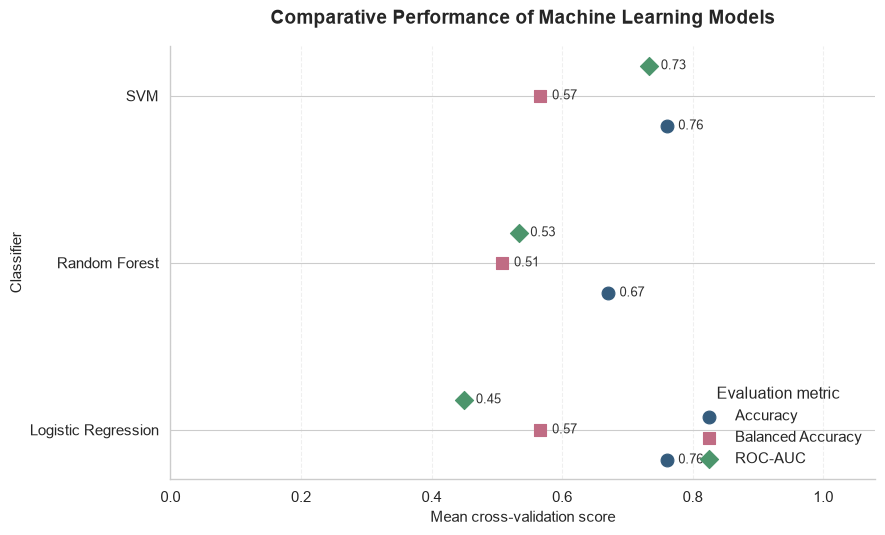

In [63]:
#Create a professional comparison visualisation

import matplotlib.pyplot as plt
import numpy as np

# Prepare model names and evaluation metrics
models = model_comparison["Model"].tolist()
metrics = ["Accuracy", "Balanced Accuracy", "ROC-AUC"]

colors = ["#355C7D", "#C06C84", "#4C956C"]
markers = ["o", "s", "D"]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Position each metric slightly apart for every model
positions = np.arange(len(models))
offsets = [-0.18, 0, 0.18]

for metric, color, marker, offset in zip(
    metrics, colors, markers, offsets
):
    values = model_comparison[metric].values

    ax.scatter(
        values,
        positions + offset,
        color=color,
        marker=marker,
        s=85,
        label=metric,
        zorder=3
    )

    # Display the score beside each point
    for value, position in zip(values, positions + offset):
        ax.text(
            value + 0.018,
            position,
            f"{value:.2f}",
            va="center",
            fontsize=9,
            color="#333333"
        )

# Format the chart
ax.set_yticks(positions)
ax.set_yticklabels(models, fontsize=11)
ax.set_xlim(0, 1.08)
ax.set_xticks(np.arange(0, 1.01, 0.2))

ax.set_xlabel("Mean cross-validation score", fontsize=11)
ax.set_ylabel("Classifier", fontsize=11)

ax.set_title(
    "Comparative Performance of Machine Learning Models",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Evaluation metric",
    frameon=False,
    loc="lower right"
)

plt.tight_layout()

# Save the publication-style figure
plt.savefig(
    "../results/figures/model_comparison_professional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Blue circle- overall proportion of correct predictions

pinnk square- performance accounting for both response groups

green diamond - ability to distinguish responders from non-responders

horizontal axis ranges from 0 to 1



For SVM
 0.76 accuracy- the model correctly classified 76% of samples on average across the cross-vlidation prediction
 
  0.57 balanced accuracy - Performance is much weaker when both response groups are given equal importance

  0.73 ROC-AUC - The model shows some ability to distinguish responders from non-responders.

Notice something interesting: accuracy is 0.76, but balanced accuracy is only 0.57.

That difference matters.
Why are the scores different?
Remember your dataset:
- 17 responders
- 5 non-responders
- 22 patients total
Your dataset is imbalanced.

Imagine a model that predicts every patient as a responder.

It would get:
17/22x100=77.3%

That means a model could achieve approximately 77% accuracy simply by predicting the majority group every time!

But it would completely fail to identify non-responders.

This is why balanced accuracy is important 

What does this tell us?
- Logistic Regression has 0.76 accuracy, but its ROC-AUC is below 0.50.
- Random Forest has the weakest balanced accuracy.
- SVM has the highest ROC-AUC of the three models.
However, none of these results establishes a reliable treatment-response predictor. We have only 22 patients and five non-responders.

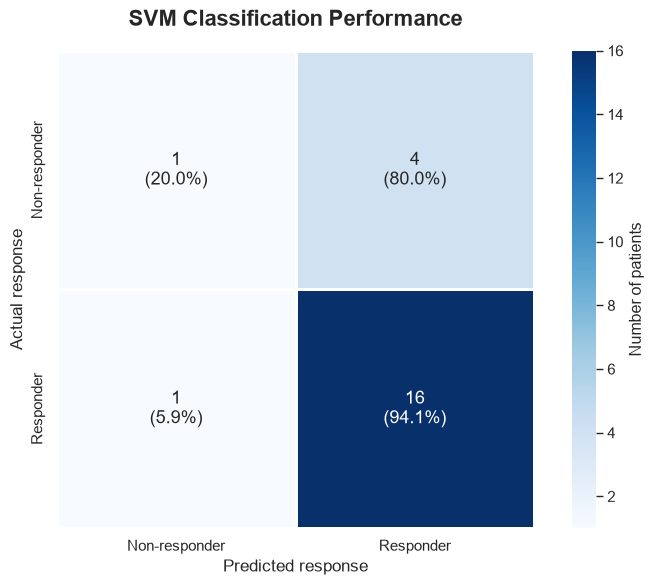

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Calculate percentages within each actual response group
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

# Display both patient counts and percentages
annotations = np.empty(cm.shape, dtype=object)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annotations[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"

labels = ["Non-responder", "Responder"]

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=annotations,
    fmt="",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    square=True,
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"label": "Number of patients"},
    annot_kws={"size": 13},
    ax=ax
)

ax.set_title(
    "SVM Classification Performance",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Predicted response", fontsize=12)
ax.set_ylabel("Actual response", fontsize=12)

plt.tight_layout()

plt.savefig(
    "../results/figures/svm_confusion_matrix_professional.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
#calculate detailed performace metrics

from sklearn.metrics import classification_report

# Evaluate predictions for both response groups
print(classification_report(
    y,
    svm_predictions,
    target_names=["Non-responder", "Responder"],
    zero_division=0
))

               precision    recall  f1-score   support

Non-responder       0.50      0.20      0.29         5
    Responder       0.80      0.94      0.86        17

     accuracy                           0.77        22
    macro avg       0.65      0.57      0.58        22
 weighted avg       0.73      0.77      0.73        22



In [68]:
#investigate feature importance


from sklearn.ensemble import RandomForestClassifier

# Train Random Forest using the preliminary 20-gene feature set
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf_model.fit(X[selected_genes], y)

# Extract gene importance scores
feature_importance = pd.DataFrame({
    "Gene": selected_genes,
    "Importance": rf_model.feature_importances_
})

# Rank genes by importance
feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

print(feature_importance.head(10))


        Gene  Importance
19    ZNF619    0.176635
0      BACH1    0.131692
5       DMWD    0.114296
15  SMIM10L1    0.086798
3    DENND5A    0.069913
16      SOD2    0.069702
12      RAF1    0.051833
10     NINJ1    0.046290
11     PTAFR    0.039782
13     RBM23    0.039236


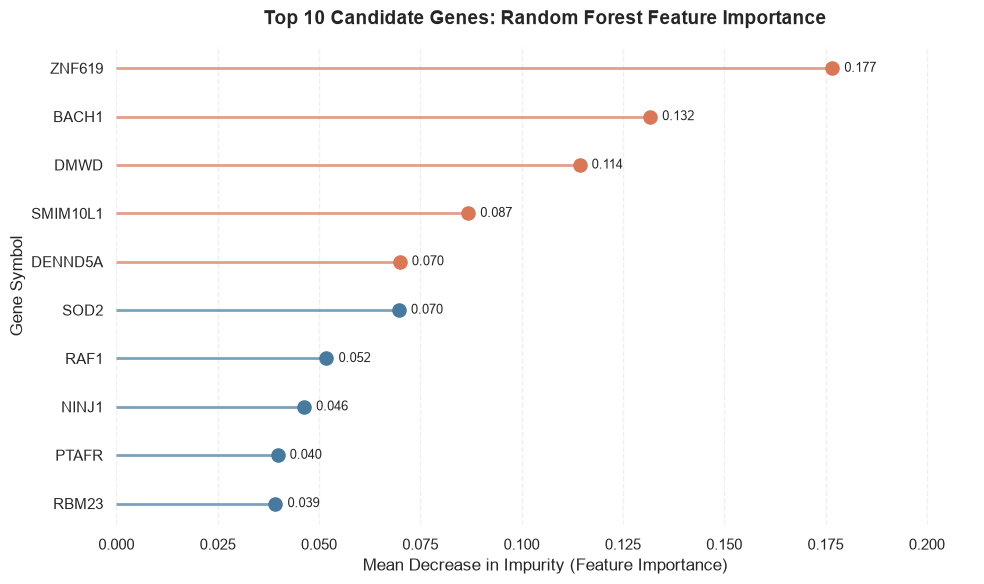

In [70]:
#gene importance plot




# Select and rank the top 10 genes
top_genes = feature_importance.head(10).copy()
top_genes = top_genes.sort_values("Importance")

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

# Highlight the top five genes
colors = [
    "#D97757" if gene in feature_importance.head(5)["Gene"].values
    else "#477A9E"
    for gene in top_genes["Gene"]
]

y_positions = np.arange(len(top_genes))

# Draw lollipop lines and points
for y, (_, row), color in zip(y_positions, top_genes.iterrows(), colors):
    ax.hlines(
        y=y,
        xmin=0,
        xmax=row["Importance"],
        color=color,
        linewidth=2,
        alpha=0.7
    )
    ax.scatter(
        row["Importance"],
        y,
        color=color,
        s=90,
        zorder=3
    )
    ax.text(
        row["Importance"] + 0.003,
        y,
        f'{row["Importance"]:.3f}',
        va="center",
        fontsize=9
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(top_genes["Gene"])

ax.set_title(
    "Top 10 Candidate Genes: Random Forest Feature Importance",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Mean Decrease in Impurity (Feature Importance)")
ax.set_ylabel("Gene Symbol")

ax.set_xlim(0, top_genes["Importance"].max() + 0.035)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)
plt.tight_layout()

plt.savefig(
    "../results/figures/top10_gene_importance_advanced.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Y-axis (Gene Symbol): The 10 genes selected for this analysis.



X-axis (Mean Decrease in Impurity): The Random Forest feature-importance score. It measures how much each gene contributed to reducing classification uncertainty across the decision trees.



Dots: Each dot represents one gene's importance score.



Horizontal lines: They connect each gene to zero, making the importance easier to compare.

ZNF619 (0.177): Highest importance. The model relied on this feature more than any other gene in this ranking.



BACH1 (0.132): Second most important.



DMWD (0.114): Third most important.



SMIM10L1 and DENND5A: Also contributed to the model's predictions.

biological meaning?

This plot gives us a shortlist of genes worth investigating biologically. It does not establish that these genes cause infliximab response or resistance.

An important observation is that ZNF619 and DMWD also appeared among your differential-expression candidates. Their appearance in both analyses makes them interesting candidates for further investigation.

biological interpretaion and pathway enrichment


In [71]:
# Prepare the selected genes for biological interpretation

candidate_genes = selected_genes

print("Number of candidate genes:", len(candidate_genes))
print("Candidate genes:")
print(candidate_genes)

Number of candidate genes: 20
Candidate genes:
Index(['BACH1', 'BASP1', 'CEP63', 'DENND5A', 'DIS3L', 'DMWD', 'EIF5A2',
       'GLT1D1', 'HLCS', 'MPZL3', 'NINJ1', 'PTAFR', 'RAF1', 'RBM23', 'RELT',
       'SMIM10L1', 'SOD2', 'TNFRSF10C', 'ZNF467', 'ZNF619'],
      dtype='str', name='gene_symbol')


In [72]:
# check the pathway libraries available in GSEApy


import gseapy as gp

# Check available pathway databases
libraries = gp.get_library_name()

[name for name in libraries if name in [
    "GO_Biological_Process_2023",
    "Reactome_2022",
    "KEGG_2021_Human",
    "MSigDB_Hallmark_2020"
]]


['GO_Biological_Process_2023',
 'KEGG_2021_Human',
 'MSigDB_Hallmark_2020',
 'Reactome_2022']

In [77]:
# Check the columns returned by GSEApy
print(enrichment_results.columns.tolist())

# Show the first five rows
print(enrichment_results.head().to_string())

['Gene_set', 'Term', 'P-value', 'Adjusted P-value', 'Old P-value', 'Old Adjusted P-value', 'Odds Ratio', 'Combined Score', 'Genes']
                     Gene_set                                                                                        Term   P-value  Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  Combined Score  Genes
0  GO_Biological_Process_2023                                               Intracellular Oxygen Homeostasis (GO:0032364)  0.004338          0.118003            0                     0  322.666667     1755.453907   SOD2
1  GO_Biological_Process_2023  Positive Regulation Of Vascular Associated Smooth Muscle Cell Differentiation (GO:1905065)  0.005419          0.118003            0                     0  241.986842     1262.645598   SOD2
2  GO_Biological_Process_2023                         Leukocyte Chemotaxis Involved In Inflammatory Response (GO:0002232)  0.005419          0.118003            0                     0  241.986842     1262.64

In [78]:
# Summarise enrichment results by pathway database
enrichment_summary = enrichment_results.groupby("Gene_set").agg(
    Total_terms=("Term", "count"),
    Significant_terms=("Adjusted P-value", lambda x: (x < 0.05).sum()),
    Best_adjusted_p=("Adjusted P-value", "min")
).reset_index()

print(enrichment_summary.to_string(index=False))

                  Gene_set  Total_terms  Significant_terms  Best_adjusted_p
GO_Biological_Process_2023          139                  0         0.118003
           KEGG_2021_Human           91                  0         0.223433
      MSigDB_Hallmark_2020           14                  1         0.016339
             Reactome_2022           56                  0         0.181426


In [79]:
# Extract pathways with adjusted p-value below 0.05
significant_pathways = enrichment_results[
    enrichment_results["Adjusted P-value"] < 0.05
].copy()

# Display the significant pathway details
print(
    significant_pathways[
        ["Gene_set", "Term", "P-value", "Adjusted P-value",
         "Odds Ratio", "Genes"]
    ].to_string(index=False)
)

            Gene_set                          Term  P-value  Adjusted P-value  Odds Ratio              Genes
MSigDB_Hallmark_2020 TNF-alpha Signaling via NF-kB 0.001167          0.016339   16.730699 NINJ1;DENND5A;SOD2


In [80]:
# Save all pathway enrichment results
enrichment_results.to_csv(
    "../results/tables/GSE107865_pathway_enrichment_all.csv",
    index=False
)

# Save statistically significant pathways
significant_pathways.to_csv(
    "../results/tables/GSE107865_significant_pathways.csv",
    index=False
)

print("Pathway enrichment results saved successfully.")

Pathway enrichment results saved successfully.


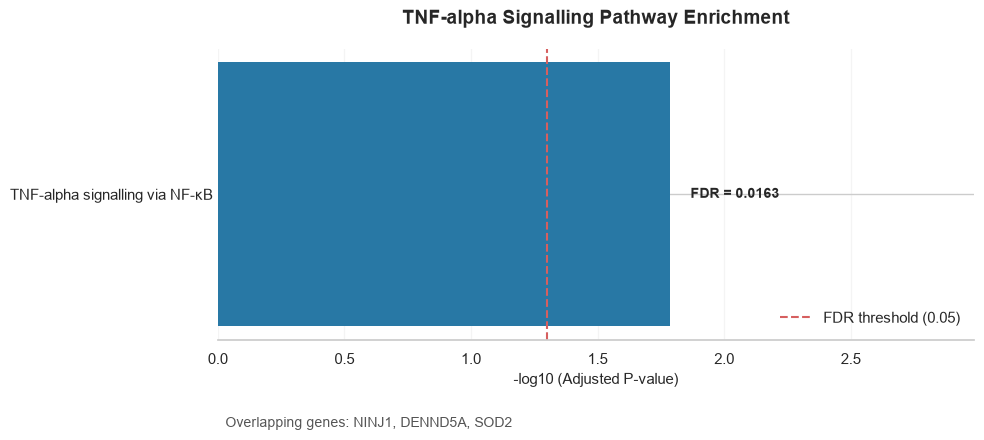

In [81]:


# Prepare pathway data
plot_data = significant_pathways.copy()
plot_data["-log10 FDR"] = -np.log10(plot_data["Adjusted P-value"])

fig, ax = plt.subplots(figsize=(10, 4.8))

# Draw pathway enrichment bar
ax.barh(
    ["TNF-alpha signalling via NF-κB"],
    plot_data["-log10 FDR"].iloc[0],
    height=0.42,
    color="#2878A5",
    edgecolor="none"
)

# Statistical significance threshold
ax.axvline(
    -np.log10(0.05),
    color="#D65F5F",
    linestyle="--",
    linewidth=1.5,
    label="FDR threshold (0.05)"
)

# Add adjusted p-value annotation
ax.text(
    plot_data["-log10 FDR"].iloc[0] + 0.08,
    0,
    f"FDR = {plot_data['Adjusted P-value'].iloc[0]:.4f}",
    va="center",
    fontsize=10,
    fontweight="bold"
)

ax.set_xlabel("-log10 (Adjusted P-value)", fontsize=11)
ax.set_title(
    "TNF-alpha Signalling Pathway Enrichment",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.text(
    0.01, -0.30,
    "Overlapping genes: NINJ1, DENND5A, SOD2",
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlim(0, plot_data["-log10 FDR"].iloc[0] + 1.2)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()

plt.savefig(
    "../results/figures/significant_pathway_enrichment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Independent validation

In [82]:
import GEOparse

# Download metadata for the independent validation cohort
gse_validation = GEOparse.get_GEO(
    "GSE42296",
    destdir="../data/raw",
    how="brief",
    annotate_gpl=False
)

print("Number of samples:", len(gse_validation.gsms))

02-Nov-2026 10:38:59 DEBUG utils - Directory ../data/raw already exists. Skipping.
02-Nov-2026 10:38:59 INFO GEOparse - Downloading http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=gsm&acc=GSE42296&form=text&view=brief to ../data/raw\GSE42296.txt
02-Nov-2026 10:39:03 DEBUG downloader - Total size: 0
02-Nov-2026 10:39:03 DEBUG downloader - md5: None
188kB [00:02, 79.8kB/s] 
02-Nov-2026 10:39:05 DEBUG downloader - Moving C:\Users\Sofie\AppData\Local\Temp\tmpz7nx6k3y to c:\crohns-treatment-response-ml\data\raw\GSE42296.txt
02-Nov-2026 10:39:05 DEBUG downloader - Successfully downloaded http://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?targ=gsm&acc=GSE42296&form=text&view=brief
02-Nov-2026 10:39:05 INFO GEOparse - Parsing ../data/raw\GSE42296.txt: 
02-Nov-2026 10:39:05 DEBUG GEOparse - SAMPLE: GSM1037296
02-Nov-2026 10:39:05 DEBUG GEOparse - SAMPLE: GSM1037297
02-Nov-2026 10:39:05 DEBUG GEOparse - SAMPLE: GSM1037298
02-Nov-2026 10:39:05 DEBUG GEOparse - SAMPLE: GSM1037299
02-Nov-2026 10:39:0

Number of samples: 78


In [83]:
# Collect sample metadata from the validation dataset
validation_samples = []

for gsm_id, gsm in gse_validation.gsms.items():
    validation_samples.append({
        "sample_id": gsm_id,
        "title": gsm.metadata.get("title", [""])[0],
        "source": gsm.metadata.get("source_name_ch1", [""])[0],
        "characteristics": "; ".join(
            gsm.metadata.get("characteristics_ch1", [])
        )
    })

validation_metadata = pd.DataFrame(validation_samples)

# Inspect sample information
print("Metadata shape:", validation_metadata.shape)
print(validation_metadata.head(10).to_string(index=False))

Metadata shape: (78, 4)
 sample_id                            title source                                                                                                                              characteristics
GSM1037296 Before treatment (week 0) IBDB14   PBMC      cell type: PBMC; subject: Patient 1; response: R - responder; treatment: Before treatment; time: week 0; disease state: Crohn's disease
GSM1037297 Before treatment (week 0) IBDB17   PBMC      cell type: PBMC; subject: Patient 2; response: R - responder; treatment: Before treatment; time: week 0; disease state: Crohn's disease
GSM1037298 Before treatment (week 0) IBDB18   PBMC      cell type: PBMC; subject: Patient 3; response: R - responder; treatment: Before treatment; time: week 0; disease state: Crohn's disease
GSM1037299 Before treatment (week 0) IBDB22   PBMC cell type: PBMC; subject: Patient 4; response: NR - non-responder; treatment: Before treatment; time: week 0; disease state: Crohn's disease
GSM1037300 Befor

In [85]:
# Extract patient, response and timepoint information
validation_metadata["patient"] = validation_metadata["characteristics"].str.extract("subject: ([^;]+)")
validation_metadata["response"] = validation_metadata["characteristics"].str.extract("response: ([^;]+)")
validation_metadata["timepoint"] = validation_metadata["characteristics"].str.extract("time: ([^;]+)")

# Check the results
print(validation_metadata["response"].value_counts())
print(validation_metadata["timepoint"].value_counts())

print("Unique patients:", validation_metadata["patient"].nunique())

response
R - responder         40
NR - non-responder    38
Name: count, dtype: int64
timepoint
week 0    39
week 2    39
Name: count, dtype: int64
Unique patients: 20


In [86]:
# Select samples collected before treatment (week 0)
baseline_validation = validation_metadata[
    validation_metadata["timepoint"] == "week 0"
].copy()

print("Baseline samples:", len(baseline_validation))
print("\nResponse distribution:")
print(baseline_validation["response"].value_counts())

print("\nUnique patients:", baseline_validation["patient"].nunique())

Baseline samples: 39

Response distribution:
response
R - responder         20
NR - non-responder    19
Name: count, dtype: int64

Unique patients: 20


In [87]:
# Check whether any patient has multiple baseline samples
print(baseline_validation["patient"].value_counts().to_string())

patient
Patient 1     2
Patient 2     2
Patient 3     2
Patient 4     2
Patient 5     2
Patient 6     2
Patient 7     2
Patient 8     2
Patient 9     2
Patient 10    2
Patient 11    2
Patient 12    2
Patient 13    2
Patient 14    2
Patient 15    2
Patient 16    2
Patient 17    2
Patient 18    2
Patient 19    2
Patient 20    1


In [88]:
#inspect duplicate samples

# Display patient IDs and their corresponding sample IDs
print(
    baseline_validation[
        ["patient", "sample_id", "response"]
    ].sort_values("patient").to_string(index=False)
)


   patient  sample_id           response
 Patient 1 GSM1037296      R - responder
 Patient 1 GSM1037336 NR - non-responder
Patient 10 GSM1037345 NR - non-responder
Patient 10 GSM1037305      R - responder
Patient 11 GSM1037346 NR - non-responder
Patient 11 GSM1037306      R - responder
Patient 12 GSM1037347 NR - non-responder
Patient 12 GSM1037307 NR - non-responder
Patient 13 GSM1037348 NR - non-responder
Patient 13 GSM1037308      R - responder
Patient 14 GSM1037349      R - responder
Patient 14 GSM1037309 NR - non-responder
Patient 15 GSM1037310      R - responder
Patient 15 GSM1037350      R - responder
Patient 16 GSM1037351      R - responder
Patient 16 GSM1037311      R - responder
Patient 17 GSM1037352      R - responder
Patient 17 GSM1037312 NR - non-responder
Patient 18 GSM1037313      R - responder
Patient 18 GSM1037353      R - responder
Patient 19 GSM1037354      R - responder
Patient 19 GSM1037314      R - responder
 Patient 2 GSM1037337 NR - non-responder
 Patient 2 GSM10

In [89]:
# Extract disease information
validation_metadata["disease"] = validation_metadata["characteristics"].str.extract(
    "disease state: ([^;]+)"
)

# Keep only Crohn's disease samples
crohns_validation = validation_metadata[
    validation_metadata["disease"] == "Crohn's disease"
].copy()

# Check the cohort
print("Crohn's samples:", len(crohns_validation))
print(crohns_validation["response"].value_counts())
print("Unique patients:", crohns_validation["patient"].nunique())

Crohn's samples: 40
response
R - responder         28
NR - non-responder    12
Name: count, dtype: int64
Unique patients: 20


In [90]:
# Select Crohn's disease samples collected at week 0
baseline_crohns = crohns_validation[
    crohns_validation["timepoint"] == "week 0"
].copy()

print("Baseline samples:", len(baseline_crohns))
print(baseline_crohns["response"].value_counts())
print("Unique patients:", baseline_crohns["patient"].nunique())

Baseline samples: 20
response
R - responder         14
NR - non-responder     6
Name: count, dtype: int64
Unique patients: 20


GSE42296 — Final validation cohort
Metric	            Primary dataset	    Validation dataset
GEO accession	        GSE107865	        GSE42296
Disease	            Crohn's disease	       Crohn's disease
Baseline samples	      22	                20
Responders	                17	                14
Non-responders          	5	                6
Timepoint	        Before treatment	       Week 0

In [93]:
# Check the platform IDs used by the samples
for gsm_id, gsm in gse_validation.gsms.items():
    print(gsm_id, gsm.metadata.get("platform_id"))
    break

GSM1037296 ['GPL6244']


In [94]:
# Check expression data for the first sample
gsm = gse_validation.gsms["GSM1037296"]

print(gsm.table.shape)
print(gsm.table.head())

(0, 0)
Empty DataFrame
Columns: []
Index: []


In [96]:
import gzip

# Open the downloaded GEO file
file_path = "../data/raw/GSE42296_series_matrix.txt.gz"

with gzip.open(file_path, "rt") as file:
    lines = file.readlines()

# Find the expression table
start = lines.index("!series_matrix_table_begin\n") + 1
end = lines.index("!series_matrix_table_end\n")

# Load expression values
from io import StringIO

expression_validation = pd.read_csv(
    StringIO("".join(lines[start:end])),
    sep="\t"
)

print("Expression matrix shape:", expression_validation.shape)
print(expression_validation.head())

Expression matrix shape: (33297, 79)
    ID_REF  GSM1037296  GSM1037297  GSM1037298  GSM1037299  GSM1037300  \
0  7892501     3.56789     2.77732     4.96492     3.48023     4.34182   
1  7892502     5.29934     5.14755     5.61253     4.59726     5.35007   
2  7892503     3.88404     4.43899     4.21384     3.41747     4.49475   
3  7892504     9.16094     9.33712     9.22489     9.38033     9.22693   
4  7892505     3.46949     3.20442     3.25990     2.58976     3.11261   

   GSM1037301  GSM1037302  GSM1037303  GSM1037304  ...  GSM1037364  \
0     4.03187     4.40343     3.48202     1.80441  ...     3.01746   
1     6.26007     5.77146     4.94384     4.37052  ...     4.59183   
2     3.96751     4.33724     3.16732     2.94884  ...     4.24751   
3     9.45308     9.12694     9.04900     8.96115  ...     8.27655   
4     3.82369     2.51297     2.81295     2.95093  ...     3.43542   

   GSM1037365  GSM1037366  GSM1037367  GSM1037368  GSM1037369  GSM1037370  \
0     2.51188     3.

In [97]:
# Get the baseline Crohn's sample IDs
baseline_ids = baseline_crohns["sample_id"].tolist()

# Select their expression values
baseline_expression = expression_validation[
    ["ID_REF"] + baseline_ids
].copy()

print("Baseline expression shape:", baseline_expression.shape)
print(baseline_expression.head())

Baseline expression shape: (33297, 21)
    ID_REF  GSM1037296  GSM1037297  GSM1037298  GSM1037299  GSM1037300  \
0  7892501     3.56789     2.77732     4.96492     3.48023     4.34182   
1  7892502     5.29934     5.14755     5.61253     4.59726     5.35007   
2  7892503     3.88404     4.43899     4.21384     3.41747     4.49475   
3  7892504     9.16094     9.33712     9.22489     9.38033     9.22693   
4  7892505     3.46949     3.20442     3.25990     2.58976     3.11261   

   GSM1037301  GSM1037302  GSM1037303  GSM1037304  ...  GSM1037306  \
0     4.03187     4.40343     3.48202     1.80441  ...     4.82395   
1     6.26007     5.77146     4.94384     4.37052  ...     5.53808   
2     3.96751     4.33724     3.16732     2.94884  ...     3.86160   
3     9.45308     9.12694     9.04900     8.96115  ...     9.33966   
4     3.82369     2.51297     2.81295     2.95093  ...     2.87481   

   GSM1037307  GSM1037308  GSM1037309  GSM1037310  GSM1037311  GSM1037312  \
0     5.21977     

In [99]:
# Read the platform annotation file
annotation_validation = pd.read_csv(
    "../data/raw/GPL6244.annot.gz",
    sep="\t",
    skiprows=27,
    low_memory=False
)

print("Annotation shape:", annotation_validation.shape)
print(annotation_validation.columns.tolist())
print(annotation_validation.head())

Annotation shape: (33298, 21)
['ID', 'Gene title', 'Gene symbol', 'Gene ID', 'UniGene title', 'UniGene symbol', 'UniGene ID', 'Nucleotide Title', 'GI', 'GenBank Accession', 'Platform_CLONEID', 'Platform_ORF', 'Platform_SPOTID', 'Chromosome location', 'Chromosome annotation', 'GO:Function', 'GO:Process', 'GO:Component', 'GO:Function ID', 'GO:Process ID', 'GO:Component ID']
        ID                                         Gene title  \
0  7896736                                                NaN   
1  7896738                                                NaN   
2  7896740  olfactory receptor family 4 subfamily F member...   
3  7896742  uncharacterized LOC100134822///septin 14///lon...   
4  7896744  olfactory receptor family 4 subfamily F member...   

                                    Gene symbol  \
0                                           NaN   
1                                           NaN   
2                        OR4F17///OR4F5///OR4F4   
3  LOC100134822///SEPT14///LIN

In [101]:
# Convert probe IDs to the same data type
baseline_expression["ID_REF"] = baseline_expression["ID_REF"].astype(str)
gene_mapping["ID"] = gene_mapping["ID"].astype(str)

# Merge expression values with gene annotations
validation_annotated = baseline_expression.merge(
    gene_mapping,
    left_on="ID_REF",
    right_on="ID"
)

print("Mapped expression shape:", validation_annotated.shape)
print(validation_annotated[["ID_REF", "Gene symbol"]].head())

Mapped expression shape: (22195, 23)
    ID_REF                                   Gene symbol
0  7896740                        OR4F17///OR4F5///OR4F4
1  7896742  LOC100134822///SEPT14///LINC00266-1///PCMTD2
2  7896744              OR4F29///OR4F21///OR4F16///OR4F3
3  7896754                   LOC100287934///LOC100287497
4  7896756                               FAM87B///FAM87A


In [102]:
# Split multiple gene symbols into individual gene names
validation_genes = validation_annotated["Gene symbol"].str.split("///").explode()

# Find candidate genes present in the validation dataset
matched_genes = [
    gene for gene in selected_genes
    if gene in validation_genes.values
]

print("Candidate genes found:", len(matched_genes))
print("Matched genes:", matched_genes)

print("Candidate genes missing:", len(selected_genes) - len(matched_genes))

Candidate genes found: 19
Matched genes: ['BACH1', 'BASP1', 'CEP63', 'DENND5A', 'DIS3L', 'DMWD', 'EIF5A2', 'GLT1D1', 'HLCS', 'MPZL3', 'NINJ1', 'PTAFR', 'RAF1', 'RBM23', 'RELT', 'SOD2', 'TNFRSF10C', 'ZNF467', 'ZNF619']
Candidate genes missing: 1


In [103]:
# Keep the first gene symbol for each probe
validation_annotated["Gene"] = validation_annotated["Gene symbol"].str.split("///").str[0]

# Calculate average expression for each gene
gene_expression_validation = validation_annotated.groupby("Gene")[baseline_ids].mean()

print("Gene expression matrix:", gene_expression_validation.shape)
print(gene_expression_validation.head())

Gene expression matrix: (20003, 20)
           GSM1037296  GSM1037297  GSM1037298  GSM1037299  GSM1037300  \
Gene                                                                    
1060P11.3    8.762107    8.816179    7.173196    8.133823    6.719861   
A1BG         6.532180    6.534650    6.704400    6.429120    6.385700   
A1CF         4.203880    4.633650    4.386550    4.426590    4.473720   
A2M          6.154930    6.093780    5.704920    6.426600    6.495750   
A2ML1        5.023410    5.040240    5.194570    5.046390    4.906330   

           GSM1037301  GSM1037302  GSM1037303  GSM1037304  GSM1037305  \
Gene                                                                    
1060P11.3    7.098307    6.398634    7.644197     8.58913    8.698796   
A1BG         6.646300    6.626640    6.436890     7.02234    6.693270   
A1CF         4.465590    4.484610    4.480570     4.96860    4.335730   
A2M          5.575910    5.550260    6.005580     5.91587    5.614100   
A2ML1        5

In [105]:
# Check which candidate genes are available in the validation matrix
available_genes = [
    gene for gene in matched_genes
    if gene in gene_expression_validation.index
]

missing_genes = [
    gene for gene in matched_genes
    if gene not in gene_expression_validation.index
]

print("Available candidate genes:", len(available_genes))
print("Missing candidate genes:", missing_genes)

Available candidate genes: 18
Missing candidate genes: ['TNFRSF10C']


In [106]:
# Identify baseline samples in each response group
responder_ids = baseline_crohns[
    baseline_crohns["response"] == "R - responder"
]["sample_id"].tolist()

non_responder_ids = baseline_crohns[
    baseline_crohns["response"] == "NR - non-responder"
]["sample_id"].tolist()

# Compare average gene expression between the groups
validation_comparison = pd.DataFrame({
    "Responder": gene_expression_validation.loc[available_genes, responder_ids].mean(axis=1),
    "Non-responder": gene_expression_validation.loc[available_genes, non_responder_ids].mean(axis=1)
})

# Calculate the expression difference
validation_comparison["Difference"] = (
    validation_comparison["Non-responder"] -
    validation_comparison["Responder"]
)

print(validation_comparison.sort_values(
    "Difference",
    ascending=False
).round(3).to_string())

         Responder  Non-responder  Difference
Gene                                         
MPZL3        7.898          8.103       0.205
BASP1        9.008          9.164       0.156
DMWD         7.271          7.334       0.064
EIF5A2       5.718          5.768       0.050
CEP63        6.809          6.854       0.046
RAF1         8.741          8.781       0.040
ZNF619       6.464          6.490       0.026
NINJ1        8.666          8.672       0.006
GLT1D1       9.062          9.000      -0.062
DIS3L        7.026          6.955      -0.071
SOD2         9.649          9.577      -0.072
ZNF467       7.763          7.669      -0.094
DENND5A      8.939          8.840      -0.099
HLCS         6.993          6.860      -0.133
RELT         8.073          7.928      -0.145
PTAFR        7.650          7.503      -0.148
BACH1        9.231          9.078      -0.153
RBM23        9.401          9.239      -0.162


In [107]:
# Get discovery dataset expression differences
discovery_comparison = de_results[
    de_results["gene"].isin(available_genes)
][["gene", "expression_difference"]].copy()

# Add independent validation results
direction_comparison = discovery_comparison.merge(
    validation_comparison,
    left_on="gene",
    right_index=True
)

print(direction_comparison.round(3).to_string(index=False))

   gene  expression_difference  Responder  Non-responder  Difference
   RELT                 -0.249      8.073          7.928      -0.145
 ZNF619                  0.557      6.464          6.490       0.026
   DMWD                  0.517      7.271          7.334       0.064
   SOD2                 -0.483      9.649          9.577      -0.072
DENND5A                 -0.530      8.939          8.840      -0.099
  BACH1                 -0.437      9.231          9.078      -0.153
  MPZL3                 -0.377      7.898          8.103       0.205
 GLT1D1                 -0.512      9.062          9.000      -0.062
  CEP63                 -0.393      6.809          6.854       0.046
   RAF1                 -0.360      8.741          8.781       0.040
  PTAFR                 -0.525      7.650          7.503      -0.148
   HLCS                  0.529      6.993          6.860      -0.133
  NINJ1                 -0.448      8.666          8.672       0.006
 EIF5A2                  0.615    

In [108]:
# Identify genes with matching expression directions
direction_comparison["Direction_consistent"] = (
    direction_comparison["expression_difference"] *
    direction_comparison["Difference"] > 0
)

# Count matching directions
consistent_count = direction_comparison["Direction_consistent"].sum()
total_count = len(direction_comparison)

print("Directionally consistent genes:", consistent_count)
print("Total genes compared:", total_count)
print("Agreement:", round(consistent_count / total_count * 100, 1), "%")

# Save the comparison
direction_comparison.to_csv(
    "../results/tables/GSE107865_GSE42296_validation_comparison.csv",
    index=False
)

Directionally consistent genes: 11
Total genes compared: 18
Agreement: 61.1 %


#validation comparision completed
now validation heatmap

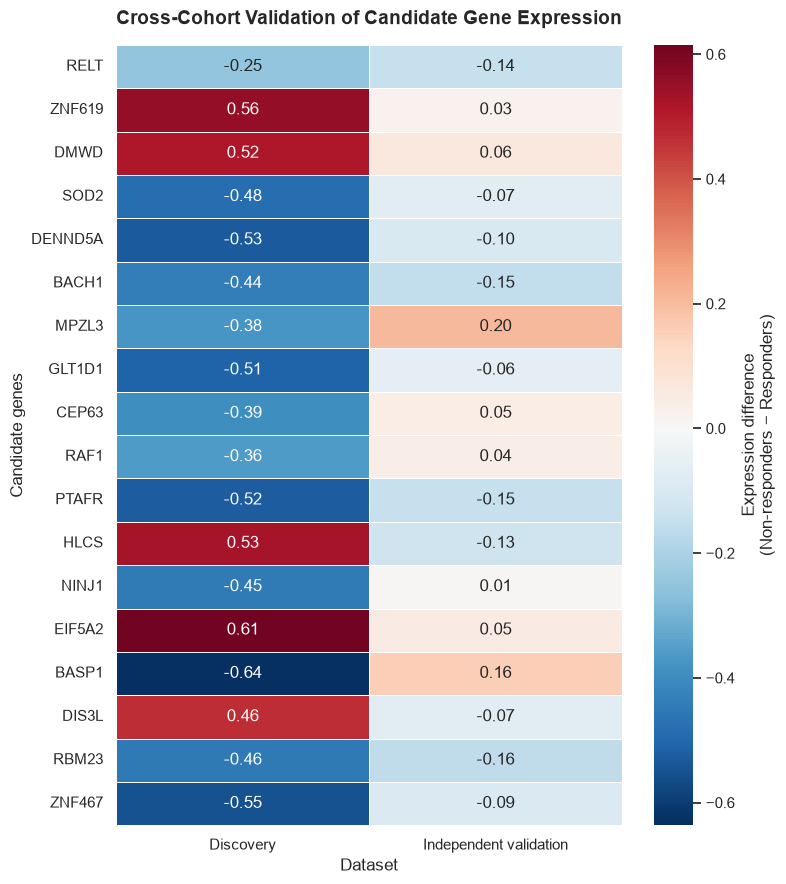

In [112]:


# Prepare actual expression differences
plot_data = direction_comparison.set_index("gene")[
    ["expression_difference", "Difference"]
].copy()

plot_data.columns = ["Discovery", "Independent validation"]

# Plot actual differences
plt.figure(figsize=(8, 9))

sns.heatmap(
    plot_data,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Expression difference\n(Non-responders − Responders)"}
)

plt.title(
    "Cross-Cohort Validation of Candidate Gene Expression",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Dataset")
plt.ylabel("Candidate genes")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "../results/figures/independent_validation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()